# FarmPulse - PlantVillage EDA

Objectif: comprendre les classes, la qualité des images et le déséquilibre avant le split et l'entraînement.

In [1]:
from pathlib import Path
from collections import Counter
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}


In [2]:
rows, invalid = [], []
for class_dir in sorted(p for p in RAW.iterdir() if p.is_dir()):
    for path in class_dir.rglob('*'):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        try:
            with Image.open(path) as image:
                image.verify()
            rows.append({'class_name': class_dir.name, 'path': str(path), 'size_bytes': path.stat().st_size})
        except (OSError, ValueError):
            invalid.append(str(path))
df = pd.DataFrame(rows)
print(f'valid images: {len(df):,}; invalid images: {len(invalid):,}; classes: {df.class_name.nunique()}')
df.class_name.value_counts().sort_values(ascending=False).head(20)


valid images: 20,638; invalid images: 0; classes: 15


class_name
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Tomato_Early_blight                            1000
Pepper__bell___Bacterial_spot                   997
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Potato___healthy                                152
Name: count, dtype: int64

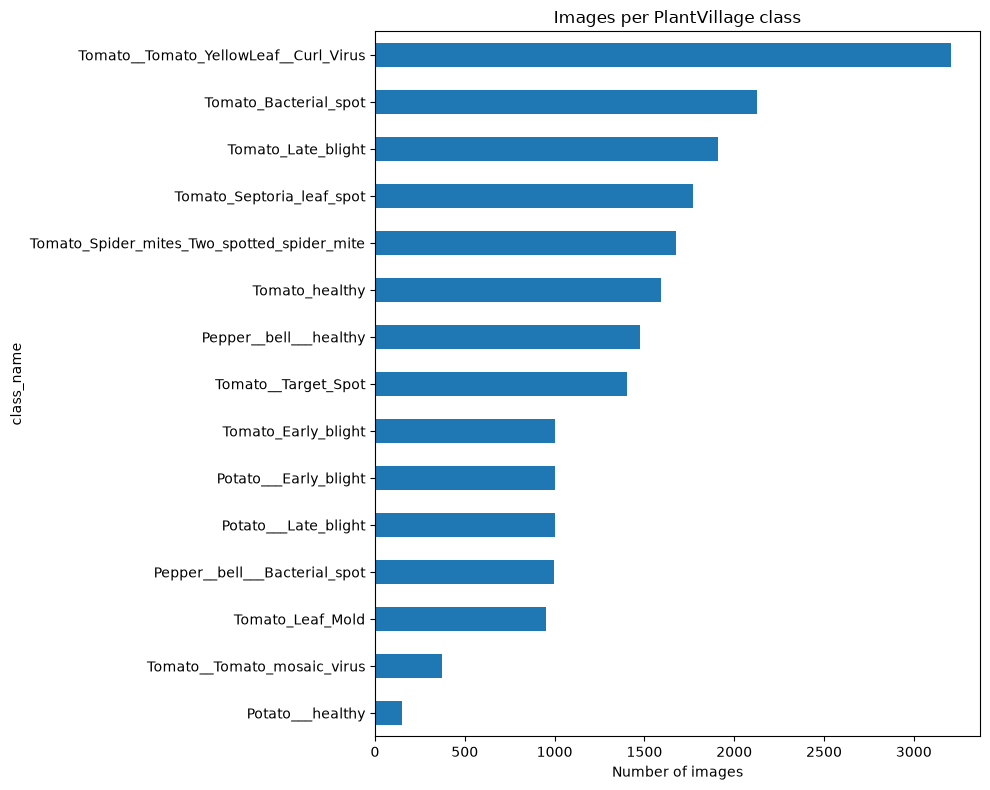

In [3]:
counts = df.class_name.value_counts().sort_values()
counts.plot(kind='barh', figsize=(10, 8), title='Images per PlantVillage class')
plt.xlabel('Number of images')
plt.tight_layout()
plt.show()


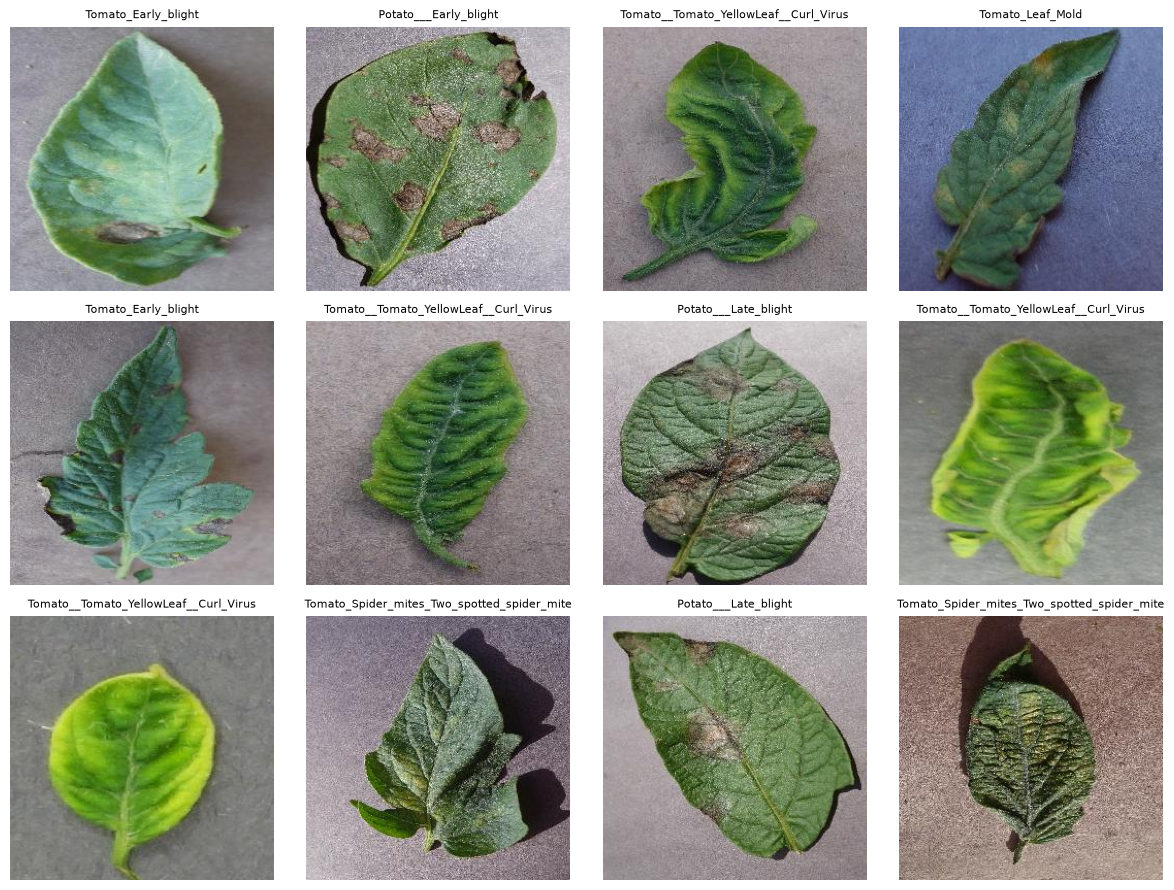

In [4]:
sample = df.sample(min(12, len(df)), random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for axis, (_, row) in zip(axes.flat, sample.iterrows()):
    axis.imshow(Image.open(row.path).convert('RGB'))
    axis.set_title(row.class_name, fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()
